#Lab

In [2]:
!pip install -q holidays

In [3]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn
!pip install -q lightgbm
!pip install -q statsforecast
!pip install -q neuralforecast
!pip install -q chronos-forecasting
!pip install -q holidays

In [4]:
import matplotlib.pyplot as plt
import urllib.request, zipfile
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn
import holidays

In [5]:
url = ("https://archive.ics.uci.edu/static/public/321/"
       "electricityloaddiagrams20112014.zip")
urllib.request.urlretrieve(url, "electricity.zip")
zipfile.ZipFile("electricity.zip").extract("LD2011_2014.txt")

raw = pd.read_csv("LD2011_2014.txt", sep=";",decimal=",",index_col=0,parse_dates=True)

print("Shape:", raw.shape)
print("Rango tiempo:", raw.index.min(),"-",raw.index.max())
print("Frecuencia:", raw.index.freq)
raw.head()

Shape: (140256, 370)
Rango tiempo: 2011-01-01 00:15:00 - 2015-01-01 00:00:00
Frecuencia: None


,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
#normalizacion indice
raw.index = raw.index.floor("h")
hourly = raw.groupby(level=0).sum()

#frecuencia horaria regular
full_range = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
hourly = hourly.reindex(full_range)

print("Shape horario:", hourly.shape)
print("Rango:", hourly.index.min(), "→", hourly.index.max())
print("Frecuencia:", hourly.index.freq)
print("NaN totales:", hourly.isna().sum().sum())
print("Horas esperadas:", len(full_range), "| presentes:", hourly.shape[0])

Shape horario: (35065, 370)
Rango: 2011-01-01 00:00:00 → 2015-01-01 00:00:00
Frecuencia: <Hour>
NaN totales: 0
Horas esperadas: 35065 | presentes: 35065


In [7]:
panel = hourly.loc["2012-01-01":"2014-12-31"].copy()
print("Horas en 2012-2014:", panel.shape[0])

#filtros NaN, series vivas
sin_nan = panel.isna().sum() == 0
print("Clientes sin NaN:", sin_nan.sum())

activos = panel.sum() > 0
print("Clientes activos:", activos.sum())

clientes_ok = panel.columns[sin_nan & activos]
panel = panel[clientes_ok]

ceros_2012_full = (panel.loc["2012-01-01":"2012-12-31"] == 0).sum()
clientes_reales = ceros_2012_full[ceros_2012_full < 24].index

panel = panel[clientes_reales].copy()

print("Clientes resultado:", panel.shape[1])
print("Observaciones horarias/serie:", panel.shape[0])
print("Observaciones totales panel:", panel.shape[0] * panel.shape[1])

Horas en 2012-2014: 26304
Clientes sin NaN: 370
Clientes activos: 370
Clientes resultado: 314
Observaciones horarias/serie: 26304
Observaciones totales panel: 8259456


In [8]:
#subconjunto 100
SEED = 42
np.random.seed(SEED)

N_CLIENTES = 100

if panel.shape[1] >= N_CLIENTES:
    clientes_sel = sorted(np.random.choice(panel.columns, size=N_CLIENTES, replace=False))
    panel_final = panel[clientes_sel].copy()
else:
    clientes_sel = list(panel.columns)
    panel_final = panel.copy()

print("Clientes finales:", panel.shape[1])
print(" - Clientes seleccionados:", len(clientes_sel))
print(" - Shape panel_100:", panel_final.shape)
print(" - Primeros 5 clientes:", clientes_sel[:5])

Clientes finales: 314
 - Clientes seleccionados: 100
 - Shape panel_100: (26304, 100)
 - Primeros 5 clientes: ['MT_004', 'MT_006', 'MT_007', 'MT_008', 'MT_010']


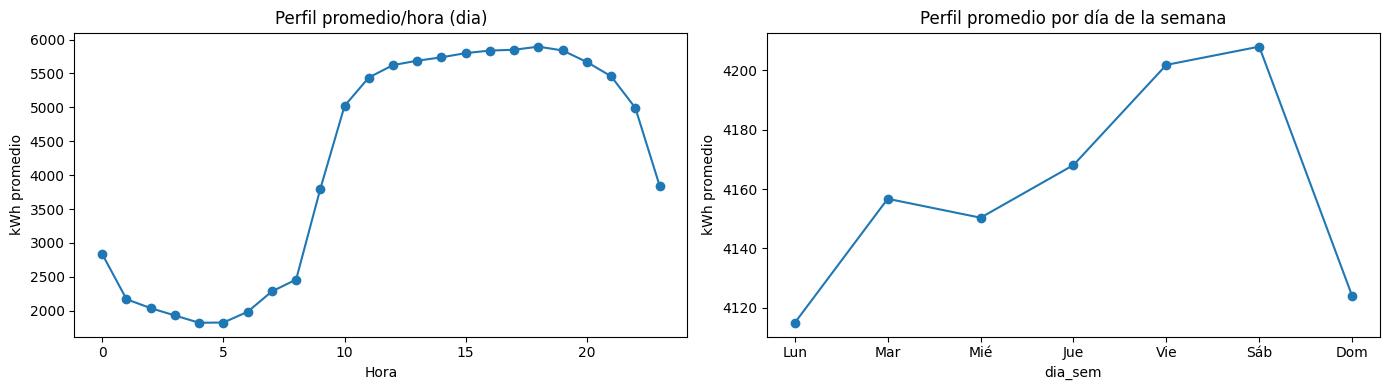

Consumo medio en feriados:    3632.59 kWh
Consumo medio en no feriados: 4175.83 kWh
Caida relativa: 13.0%


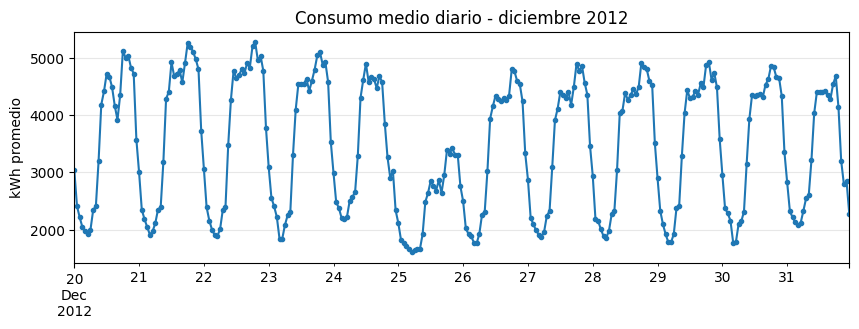

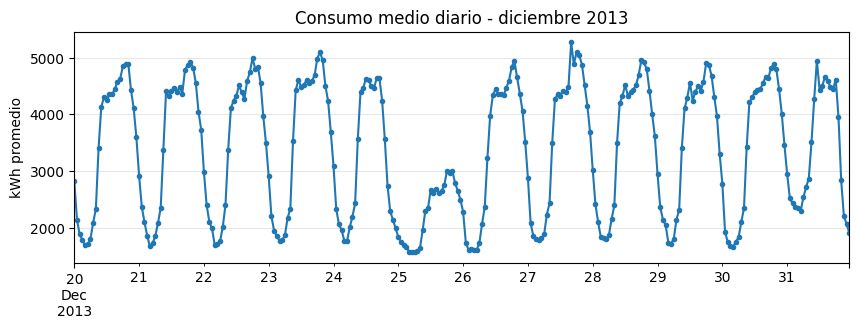

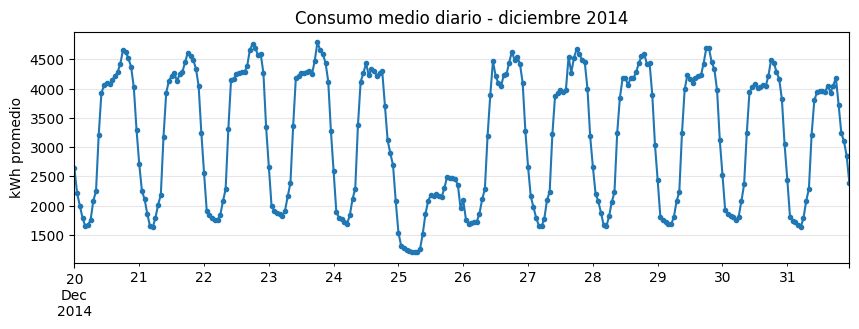

Minimo : 24.11 kWh
Mediana: 599.92 kWh
Maximo : 200529.12 kWh
Ratio max/min: 8318.0x


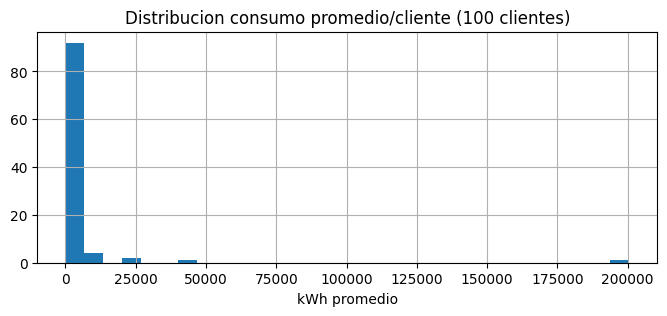

In [9]:
#expolacion visual
df = panel_final.copy()
df["hora"] = df.index.hour
df["dia_sem"] = df.index.dayofweek

perfil_hora = df.groupby("hora")[clientes_sel].mean().mean(axis=1)
perfil_dia  = df.groupby("dia_sem")[clientes_sel].mean().mean(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
perfil_hora.plot(ax=ax[0], marker="o")
ax[0].set_title("Perfil promedio/hora (dia)")
ax[0].set_xlabel("Hora"); ax[0].set_ylabel("kWh promedio")

perfil_dia.plot(ax=ax[1], marker="o")
ax[1].set_xticks(range(7))
ax[1].set_xticklabels(["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"])
ax[1].set_title("Perfil promedio por día de la semana")
ax[1].set_ylabel("kWh promedio")
plt.tight_layout(); plt.show()

#feriadaos
feriados_pt = holidays.Portugal(years=[2012, 2013, 2014])
fechas_feriados = pd.to_datetime(list(feriados_pt.keys())).normalize()
df["feriado"] = df.index.normalize().isin(fechas_feriados)

prom = df[clientes_sel].mean(axis=1)
print(f"Consumo medio en feriados:    {prom[df['feriado']].mean():.2f} kWh")
print(f"Consumo medio en no feriados: {prom[~df['feriado']].mean():.2f} kWh")
print(f"Caida relativa: {100*(1 - prom[df['feriado']].mean()/prom[~df['feriado']].mean()):.1f}%")

for anio in [2012, 2013, 2014]:
    ventana = prom.loc[f"{anio}-12-20":f"{anio}-12-31"]
    ventana.plot(figsize=(10,3), marker=".")
    plt.title(f"Consumo medio diario - diciembre {anio}")
    plt.ylabel("kWh promedio"); plt.grid(alpha=.3); plt.show()


prom_cliente = panel_final.mean()
print("Minimo :", f"{prom_cliente.min():.2f} kWh")
print("Mediana:", f"{prom_cliente.median():.2f} kWh")
print("Maximo :", f"{prom_cliente.max():.2f} kWh")
print("Ratio max/min:", f"{prom_cliente.max()/prom_cliente.min():.1f}x")

prom_cliente.hist(bins=30, figsize=(8,3))
plt.title(f"Distribucion consumo promedio/cliente ({len(clientes_sel)} clientes)")
plt.xlabel("kWh promedio")
plt.show()

In [10]:
TRAIN_END = "2014-06-30 23:00:00"
VAL_START = "2014-07-01 00:00:00"
VAL_END   = "2014-09-30 23:00:00"
TEST_START = "2014-10-01 00:00:00"
TEST_END   = "2014-12-31 23:00:00"

train = panel_final.loc[:TRAIN_END]
val   = panel_final.loc[VAL_START:VAL_END]
test  = panel_final.loc[TEST_START:TEST_END]

print(f"Train: {train.index.min()} - {train.index.max()}  ({len(train)} horas)")
print(f"Val  : {val.index.min()} - {val.index.max()}  ({len(val)} horas)")
print(f"Test : {test.index.min()} - {test.index.max()}  ({len(test)} horas)")

#verficaicon
assert train.index.max() < val.index.min()
assert val.index.max() < test.index.min()
print("- Split sin solapamiento")

Train: 2012-01-01 00:00:00 - 2014-06-30 23:00:00  (21888 horas)
Val  : 2014-07-01 00:00:00 - 2014-09-30 23:00:00  (2208 horas)
Test : 2014-10-01 00:00:00 - 2014-12-31 23:00:00  (2208 horas)
- Split sin solapamiento


In [11]:
#normalizacion zscore
mu_train  = train.mean()
std_train = train.std()

std_train = std_train.replace(0, 1.0)

stats_norm = pd.DataFrame({"mu": mu_train, "std": std_train})

def normalizar(df):
    return (df - mu_train) / std_train

train_n = normalizar(train)
val_n   = normalizar(val)
test_n  = normalizar(test)

print("Train normalizado: media (aprox.) =", train_n.mean().mean().round(4),"| std (aprox.) =", train_n.std().mean().round(4))
print("Val normalizado: media (aprox.)", val_n.mean().mean().round(4),"| std (aprox.) =", val_n.std().mean().round(4))

#covariables
def construir_covariables(idx, feriados_pt):
    #dataframe coveariables
    cov = pd.DataFrame(index=idx)
    cov["hora"]      = idx.hour
    cov["dia_sem"]   = idx.dayofweek
    cov["mes"]       = idx.month
    cov["feriado"]   = idx.normalize().isin(pd.to_datetime(list(feriados_pt.keys())).normalize()).astype(int)

    cov["hora_sin"]  = np.sin(2*np.pi*cov["hora"]/24)
    cov["hora_cos"]  = np.cos(2*np.pi*cov["hora"]/24)
    cov["dia_sin"]   = np.sin(2*np.pi*cov["dia_sem"]/7)
    cov["dia_cos"]   = np.cos(2*np.pi*cov["dia_sem"]/7)
    cov["mes_sin"]   = np.sin(2*np.pi*(cov["mes"]-1)/12)
    cov["mes_cos"]   = np.cos(2*np.pi*(cov["mes"]-1)/12)

    #one-hot hora y dia)
    hora_dummies = pd.get_dummies(cov["hora"], prefix="h", dtype=float)
    dia_dummies  = pd.get_dummies(cov["dia_sem"], prefix="d", dtype=float)

    cov = pd.concat([cov, hora_dummies, dia_dummies], axis=1)
    return cov

cov_all = construir_covariables(panel_final.index, holidays.Portugal(years=[2012,2013,2014]))

COLS_COV = [c for c in cov_all.columns if c not in ["hora","dia_sem","mes"]]
print("Covariables usadas en el modelo:", len(COLS_COV))
print(COLS_COV)

Train normalizado: media (aprox.) = -0.0 | std (aprox.) = 1.0
Val normalizado: media (aprox.) 0.205 | std (aprox.) = 0.9432
Covariables usadas en el modelo: 38
['feriado', 'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'mes_sin', 'mes_cos', 'h_0', 'h_1', 'h_2', 'h_3', 'h_4', 'h_5', 'h_6', 'h_7', 'h_8', 'h_9', 'h_10', 'h_11', 'h_12', 'h_13', 'h_14', 'h_15', 'h_16', 'h_17', 'h_18', 'h_19', 'h_20', 'h_21', 'h_22', 'h_23', 'd_0', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6']


In [12]:
class PanelWindowDataset(Dataset):
    #Dataset ventanas panel de series.
    def __init__(self, series_norm, cov, L, H, stride=1):
        """
        series_norm: array (T, N) series normalizadas
        cov: DataFrame (T, n_cov) covariables mismo indice
        """
        self.series = torch.tensor(series_norm.values, dtype=torch.float32)  # (T, N)
        self.cov    = torch.tensor(cov[COLS_COV].values, dtype=torch.float32)  # (T, n_cov)
        self.L, self.H, self.stride = L, H, stride
        self.T, self.N = self.series.shape

        self.t_inicios = list(range(0, self.T - L - H + 1, stride))

    def __len__(self):
        return self.N * len(self.t_inicios)

    def __getitem__(self, idx):
        n = idx // len(self.t_inicios)
        t = self.t_inicios[idx % len(self.t_inicios)]

        x_serie = self.series[t : t + self.L, n].unsqueeze(-1)#(L, 1)
        x_cov = self.cov[t : t + self.L]#(L, n_cov)
        # X concatenado: (L, 1+n_cov)
        X = torch.cat([x_serie, x_cov], dim=-1)

        y = self.series[t + self.L : t + self.L + self.H, n]

        return X, y
#conteo ventanas
L, H, STRIDE = 168, 24, 1

ds_train = PanelWindowDataset(train_n, cov_all.loc[train_n.index], L, H, STRIDE)
ds_val   = PanelWindowDataset(val_n,   cov_all.loc[val_n.index],   L, H, STRIDE)
ds_test  = PanelWindowDataset(test_n,  cov_all.loc[test_n.index],  L, H, STRIDE)

print(f"Ventanas Train: {len(ds_train):,}")
print(f"Ventanas Val: {len(ds_val):,}")
print(f"Ventanas Test: {len(ds_test):,}")
print(f"Total: {len(ds_train)+len(ds_val)+len(ds_test):,}")

X_sample, y_sample = ds_train[0]
print(f"\nX shape: {X_sample.shape} - (L, 1+n_cov)")
print(f"y shape: {y_sample.shape} - (H,)")

Ventanas Train: 2,169,700
Ventanas Val: 201,700
Ventanas Test: 201,700
Total: 2,573,100

X shape: torch.Size([168, 39]) - (L, 1+n_cov)
y shape: torch.Size([24]) - (H,)


In [13]:
def backtest(predict_fn, test_df, history_seed, H=24):
    origenes = pd.date_range(test_df.index.min().normalize(), test_df.index.max().normalize(), freq="D")
    print(f"Origenes: {len(origenes)}  ({origenes[0]} - {origenes[-1]})")

    history = history_seed.copy()

    preds_list, real_list = [], []
    for origin in origenes:
        y_hat = predict_fn(history, origin, H)
        ts_obj = pd.date_range(origin, periods=H, freq="h")
        real   = test_df.loc[ts_obj]

        preds_list.append(pd.DataFrame(y_hat, index=ts_obj, columns=test_df.columns))
        real_list.append(real)

        history = pd.concat([history, real])

    return pd.concat(preds_list), pd.concat(real_list)

def metricas(preds, real):
    e  = preds.values - real.values
    ae = np.abs(e); re = np.abs(real.values)
    return {
        "MAE":  ae.mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "WAPE": ae.sum() / re.sum(),
        "MAPE": (ae / (re + 1e-6)).mean() * 100,
    }

def mase(preds, real, train_df, season=24):
    den = (train_df - train_df.shift(season)).abs().mean().replace(0, np.nan)
    num = (preds - real).abs().mean()
    return (num / den).mean()

history_seed = pd.concat([train, val])

def make_seasonal_naive(season):
    def predict_fn(history, origin, H):
        last_cycle = history.iloc[-season:].values
        reps = int(np.ceil(H / season))
        return np.tile(last_cycle, (reps, 1))[:H]
    return predict_fn

def naive_predict(history, origin, H):
    return np.tile(history.iloc[-1:].values, (H, 1))

preds_naive, real_test = backtest(naive_predict, test, history_seed, H=24)
preds_sn24,  _  = backtest(make_seasonal_naive(24),  test, history_seed, H=24)
preds_sn168, _ = backtest(make_seasonal_naive(168), test, history_seed, H=24)

for nombre, p in [("Naive", preds_naive),("Seasonal Naive 24h", preds_sn24),("Seasonal Naive 168h", preds_sn168)]:
    m = metricas(p, real_test)
    print(f"\n{nombre}")
    print(f"  MAE  = {m['MAE']:.4f} kWh")
    print(f"  RMSE = {m['RMSE']:.4f} kWh")
    print(f"  WAPE = {m['WAPE']*100:.2f}%")
    print(f"  MAPE = {m['MAPE']:.2f}%")
    print(f"  MASE = {mase(p, real_test, train, season=24):.4f}")

Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)

Naive
  MAE  = 1526.2041 kWh
  RMSE = 11282.2393 kWh
  WAPE = 41.02%
  MAPE = 351554232.20%
  MASE = 3.9267

Seasonal Naive 24h
  MAE  = 320.1815 kWh
  RMSE = 2644.0850 kWh
  WAPE = 8.61%
  MAPE = 482558169.03%
  MASE = 1.0666

Seasonal Naive 168h
  MAE  = 400.4488 kWh
  RMSE = 4339.2617 kWh
  WAPE = 10.76%
  MAPE = 492937166.34%
  MASE = 1.1410


In [14]:
#modelos
class DLinear(nn.Module):
    def __init__(self, L, H, kernel_size=25, individual=False):
        super().__init__()
        self.L, self.H = L, H
        self.kernel_size = kernel_size
        self.moving_avg = nn.AvgPool1d(kernel_size=kernel_size, stride=1,
                                        padding=kernel_size//2, count_include_pad=False)
        self.linear_trend   = nn.Linear(L, H)
        self.linear_season  = nn.Linear(L, H)

    def forward(self, x):
        #x:(B, L, 1)- (B, 1, L)
        if x.dim() ==3:
            x = x.squeeze(-1)#(B, L)
        x_pool = x.unsqueeze(1)#(B, 1, L)
        trend    = self.moving_avg(x_pool).squeeze(1)#(B, L)
        season   = x - trend
        return self.linear_trend(trend) + self.linear_season(season)#(B, H)


class NLinear(nn.Module):
    def __init__(self, L, H):
        super().__init__()
        self.linear = nn.Linear(L, H)

    def forward(self, x):
        if x.dim()==3:
            x = x.squeeze(-1)#(B, L)
        last = x[:, -1:]#(B, 1)
        x_norm = x -last
        return self.linear(x_norm)+last

def entrenar_modelo(model, ds_train, ds_val, epochs=30, lr=1e-3, batch_size=256, device=None, patience=5, verbose=True):
    #entrenar early stopping en val (MAE)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True,  num_workers=2)
    dl_val   = DataLoader(ds_val,   batch_size=batch_size, shuffle=False, num_workers=2)

    opt   = torch.optim.Adam(model.parameters(), lr=lr)
    loss  = nn.L1Loss()#MAE

    best_val, best_state, patience_ctr = np.inf, None, 0
    hist = {"train": [], "val": []}

    for ep in range(1, epochs+1):
        model.train()
        tl = 0.0
        for X, y in dl_train:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            pred = model(X)
            l = loss(pred, y)
            l.backward(); opt.step()
            tl += l.item() * len(X)
        tl /= len(ds_train)

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for X, y in dl_val:
                X, y = X.to(device), y.to(device)
                vl += loss(model(X), y).item() * len(X)
        vl /= len(ds_val)
        hist["train"].append(tl); hist["val"].append(vl)

        if verbose:
            print(f"Ep {ep:02d} | train {tl:.4f} | val {vl:.4f}")

        #early stopping
        if vl < best_val:
            best_val = vl
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"Early stop en epoch {ep} (best val={best_val:.4f})")
                break

    model.load_state_dict(best_state)
    return model, hist

Device: cpu
DLinear params: 8,112
Ep 01 | train 0.2172 | val 0.2265
Ep 02 | train 0.2110 | val 0.2269
Ep 03 | train 0.2110 | val 0.2271
Ep 04 | train 0.2110 | val 0.2265
Ep 05 | train 0.2110 | val 0.2266
Ep 06 | train 0.2110 | val 0.2266
Early stop en epoch 6 (best val=0.2265)
NLinear params: 4,056
Ep 01 | train 0.2186 | val 0.2268
Ep 02 | train 0.2108 | val 0.2262
Ep 03 | train 0.2108 | val 0.2262
Ep 04 | train 0.2108 | val 0.2266
Ep 05 | train 0.2108 | val 0.2269
Ep 06 | train 0.2108 | val 0.2265
Ep 07 | train 0.2108 | val 0.2264
Early stop en epoch 7 (best val=0.2262)


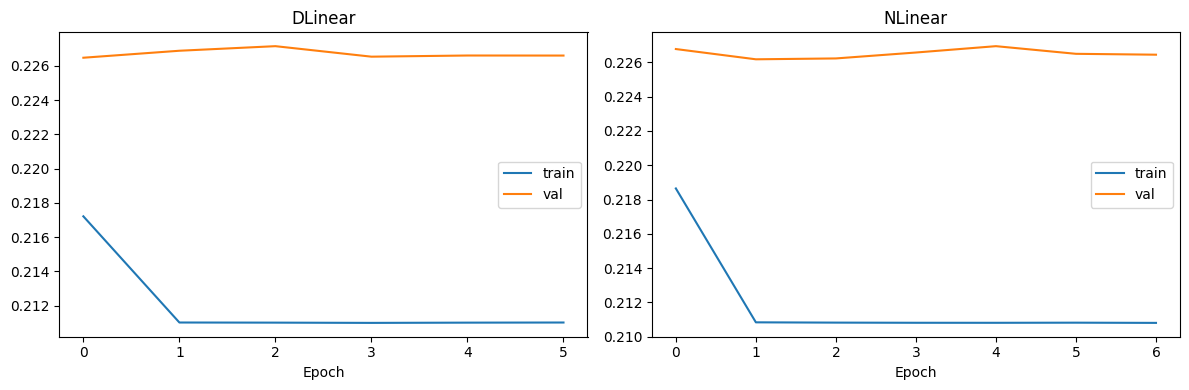

In [15]:
def make_torch_predict(model, cov_all, L, H, mu_train, std_train,
                       device=None, series_only=False):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.eval().to(device)

    # Pre-convertimos a tensores (N,) y luego a (N, 1)
    mu_t  = torch.tensor(mu_train.values,  dtype=torch.float32, device=device).view(-1, 1)  # (N,1)
    std_t = torch.tensor(std_train.values, dtype=torch.float32, device=device).view(-1, 1)  # (N,1)

    def predict_fn(history, origin, H):
        window   = history.iloc[-L:].values
        N        = window.shape[1]
        window_n = (window - mu_train.values) / std_train.values

        ts_in    = history.index[-L:]
        cov_in   = cov_all.loc[ts_in, COLS_COV].values
        cov_in_t = torch.tensor(cov_in, dtype=torch.float32, device=device)
        cov_in_t = cov_in_t.unsqueeze(0).expand(N, -1, -1)

        x_serie = torch.tensor(window_n.T, dtype=torch.float32, device=device).unsqueeze(-1)

        X = x_serie if series_only else torch.cat([x_serie, cov_in_t], dim=-1)

        with torch.no_grad():
            y_norm = model(X)

        y = y_norm * std_t + mu_t
        return y.cpu().numpy().T

    return predict_fn

class SeriesOnlyDataset(PanelWindowDataset):
    def __getitem__(self, idx):
        X_full, y = super().__getitem__(idx)
        return X_full[:, :1], y

ds_train_lin = SeriesOnlyDataset(train_n, cov_all.loc[train_n.index], L=168, H=24)
ds_val_lin   = SeriesOnlyDataset(val_n,   cov_all.loc[val_n.index],   L=168, H=24)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

L, H = 168, 24

#DLinear
model_dl = DLinear(L=L, H=H, kernel_size=25).to(DEVICE)
print(f"DLinear params: {sum(p.numel() for p in model_dl.parameters()):,}")
model_dl, hist_dl = entrenar_modelo(model_dl, ds_train_lin, ds_val_lin,epochs=30, lr=1e-3, batch_size=512, device=DEVICE)

#NLinear
model_nl = NLinear(L=L, H=H).to(DEVICE)
print(f"NLinear params: {sum(p.numel() for p in model_nl.parameters()):,}")
model_nl, hist_nl = entrenar_modelo(model_nl, ds_train_lin, ds_val_lin, epochs=30, lr=1e-3, batch_size=512, device=DEVICE)

#curv perdida
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_dl["train"], label="train"); ax[0].plot(hist_dl["val"], label="val")
ax[0].set_title("DLinear"); ax[0].legend(); ax[0].set_xlabel("Epoch")
ax[1].plot(hist_nl["train"], label="train"); ax[1].plot(hist_nl["val"], label="val")
ax[1].set_title("NLinear"); ax[1].legend(); ax[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

In [16]:
pred_fn_dl = make_torch_predict(model_dl, cov_all, L, H, mu_train, std_train,DEVICE, series_only=True)
pred_fn_nl = make_torch_predict(model_nl, cov_all, L, H, mu_train, std_train, DEVICE, series_only=True)

preds_dl, real_test = backtest(pred_fn_dl, test, history_seed, H=24)
preds_nl, _ = backtest(pred_fn_nl, test, history_seed, H=24)

for nombre, p in [("DLinear", preds_dl), ("NLinear", preds_nl)]:
    m = metricas(p, real_test)
    print(f"\n{nombre}")
    print(f"  MAE  = {m['MAE']:.2f} kWh")
    print(f"  RMSE = {m['RMSE']:.2f} kWh")
    print(f"  WAPE = {m['WAPE']*100:.2f}%")
    print(f"  MASE = {mase(p, real_test, train, season=24):.4f}")

Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)

DLinear
  MAE  = 303.14 kWh
  RMSE = 2696.88 kWh
  WAPE = 8.15%
  MASE = 0.9165

NLinear
  MAE  = 303.75 kWh
  RMSE = 2691.68 kWh
  WAPE = 8.16%
  MASE = 0.9165


In [17]:
RESULTADOS = {}
def registrar(nombre, preds, real, train_df):
    m = metricas(preds, real)
    m["MASE"] = mase(preds, real, train_df, season=24)
    RESULTADOS[nombre] = {"preds": preds, "metricas": m}
    print(f"{nombre:25s} | MAE {m['MAE']:7.2f} | WAPE {m['WAPE']*100:5.2f}% | MASE {m['MASE']:.4f}")

registrar("Naive", preds_naive,real_test, train)
registrar("SeasonalNaive24", preds_sn24, real_test, train)
registrar("SeasonalNaive168", preds_sn168,real_test, train)
registrar("DLinear",preds_dl,real_test, train)
registrar("NLinear",preds_nl,real_test, train)

Naive                     | MAE 1526.20 | WAPE 41.02% | MASE 3.9267
SeasonalNaive24           | MAE  320.18 | WAPE  8.61% | MASE 1.0666
SeasonalNaive168          | MAE  400.45 | WAPE 10.76% | MASE 1.1410
DLinear                   | MAE  303.14 | WAPE  8.15% | MASE 0.9165
NLinear                   | MAE  303.75 | WAPE  8.16% | MASE 0.9165



--------------------------------------------------
Entrenando DLinear con L=48, H=24
--------------------------------------------------
Early stop en epoch 7 (best val=0.2456)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
- MASE=1.0125 | MAE=310.44 | WAPE=8.34%
- params=2,352 | epochs=7 | t=947.6s

--------------------------------------------------
Entrenando DLinear con L=168, H=24
--------------------------------------------------
Early stop en epoch 12 (best val=0.2260)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
- MASE=0.9178 | MAE=309.84 | WAPE=8.33%
- params=8,112 | epochs=12 | t=1989.9s

--------------------------------------------------
Entrenando DLinear con L=336, H=24
--------------------------------------------------
Early stop en epoch 9 (best val=0.2194)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
- MASE=0.8948 | MAE=297.25 | WAPE=7.99%
- params=16,176 | epochs=9 | t=1856.1s

--------------------------------------------------------

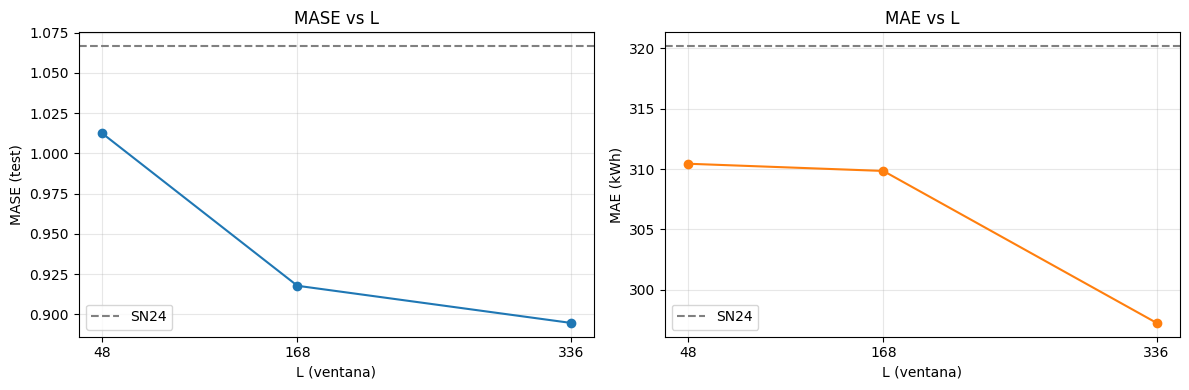

In [18]:
#preubas
#Dlinaer
import time

resultados_L = {}

for L_val in [48, 168, 336]:
    print(f"\n{'-'*50}")
    print(f"Entrenando DLinear con L={L_val}, H=24")
    print(f"{'-'*50}")

    ds_tr = SeriesOnlyDataset(train_n, cov_all.loc[train_n.index], L=L_val, H=24)
    ds_va = SeriesOnlyDataset(val_n,   cov_all.loc[val_n.index],   L=L_val, H=24)

    model = DLinear(L=L_val, H=24, kernel_size=25).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())

    t0 = time.time()
    model, hist = entrenar_modelo(model, ds_tr, ds_va, epochs=20, lr=1e-3, batch_size=512, device=DEVICE, verbose=False)
    t_train = time.time()-t0

    pf = make_torch_predict(model, cov_all, L_val, 24, mu_train, std_train, DEVICE, series_only=True)
    pr, _ = backtest(pf, test, history_seed)

    m = metricas(pr, real_test)
    m["MASE"] = mase(pr, real_test, train, season=24)

    resultados_L[L_val] = {
        "MASE": m["MASE"],
        "MAE": m["MAE"],
        "WAPE": m["WAPE"],
        "params": n_params,
        "epochs": len(hist["train"]),
        "tiempo_train_seg": t_train,
        "preds": pr
    }

    print(f"- MASE={m['MASE']:.4f} | MAE={m['MAE']:.2f} | WAPE={m['WAPE']*100:.2f}%")
    print(f"- params={n_params:,} | epochs={len(hist['train'])} | t={t_train:.1f}s")

print("\n" + "-"*60)
print("RESUMEN - VARIAR L CON DLINEAR")
print("-"*60)
df_L = pd.DataFrame({
    L_val: {
        "MASE": r["MASE"], "MAE": r["MAE"], "WAPE (%)": r["WAPE"]*100,"Params": r["params"], "Epochs": r["epochs"], "Tiempo (s)": r["tiempo_train_seg"]
    }
    for L_val, r in resultados_L.items()
}).T
print(df_L.round(4))

#graficas
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
L_vals = list(resultados_L.keys())
mases = [resultados_L[L]["MASE"] for L in L_vals]
maes = [resultados_L[L]["MAE"]  for L in L_vals]
ax[0].plot(L_vals, mases, marker="o", color="C0")
ax[0].axhline(y=mase(preds_sn24, real_test, train), color="gray", ls="--", label="SN24")
ax[0].set_xlabel("L (ventana)"); ax[0].set_ylabel("MASE (test)")
ax[0].set_title("MASE vs L"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_xticks(L_vals)

ax[1].plot(L_vals, maes, marker="o", color="C1")
ax[1].axhline(y=metricas(preds_sn24, real_test)["MAE"], color="gray", ls="--", label="SN24")
ax[1].set_xlabel("L (ventana)"); ax[1].set_ylabel("MAE (kWh)")
ax[1].set_title("MAE vs L"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_xticks(L_vals)
plt.tight_layout(); plt.show()

for L_val, r in resultados_L.items():
    RESULTADOS[f"DLinear_L{L_val}"] = {"preds": r["preds"], "metricas": {"MASE": r["MASE"], "MAE": r["MAE"], "WAPE": r["WAPE"]}}

In [ ]:
#variacion meses
resultados_H = {}

for meses in [3, 12, 30]:
    print(f"\n{'-'*50}")
    print(f"Entrenando DLinear con {meses} meses de historia")
    print(f"{'-'*50}")

    cutoff = train.index.max() - pd.DateOffset(months=meses)
    train_cut = train.loc[cutoff:]
    print(f"  Train cut: {train_cut.index.min()} - {train_cut.index.max()} ({len(train_cut)} horas)")

    mu_cut  = train_cut.mean()
    std_cut = train_cut.std().replace(0, 1.0)
    train_cut_n = (train_cut - mu_cut) /std_cut
    val_n_cut   = (val - mu_cut)/std_cut

    ds_tr = SeriesOnlyDataset(train_cut_n, cov_all.loc[train_cut.index], L=168, H=24)
    ds_va = SeriesOnlyDataset(val_n_cut,   cov_all.loc[val.index],      L=168, H=24)

    model = DLinear(L=168, H=24).to(DEVICE)
    t0 = time.time()
    model, hist = entrenar_modelo(model, ds_tr, ds_va, epochs=20, lr=1e-3,batch_size=512, device=DEVICE, verbose=False)
    t_train = time.time() - t0

    pf = make_torch_predict(model, cov_all, 168, 24, mu_cut, std_cut,
                            DEVICE, series_only=True)
    pr, _ = backtest(pf, test, history_seed)

    m = metricas(pr, real_test)
    m["MASE"] = mase(pr, real_test, train, season=24)

    resultados_H[meses] = {
        "MASE": m["MASE"], "MAE": m["MAE"], "WAPE": m["WAPE"],
        "horas_train": len(train_cut),
        "tiempo_train_seg": t_train,
        "preds": pr
    }
    print(f"- MASE={m['MASE']:.4f} | MAE={m['MAE']:.2f} | WAPE={m['WAPE']*100:.2f}%")


print("\n" + "-"*60)
print("RESUMEN - VARIAR MESES DE HISTORIA")
print("-"*60)
df_H = pd.DataFrame({
    f"{m} meses": {
        "MASE": r["MASE"], "MAE": r["MAE"], "WAPE (%)": r["WAPE"]*100,
        "Horas train": r["horas_train"], "Tiempo (s)": r["tiempo_train_seg"]
    }
    for m, r in resultados_H.items()
}).T
print(df_H.round(4))

#grafica
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
meses_list = list(resultados_H.keys())
ax[0].plot(meses_list, [resultados_H[m]["MASE"] for m in meses_list], marker="o")
ax[0].axhline(y=mase(preds_sn24, real_test, train), color="gray", ls="--", label="SN24")
ax[0].set_xlabel("Meses de historia"); ax[0].set_ylabel("MASE (test)")
ax[0].set_title("MASE vs Historia de entrenamiento"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_xticks(meses_list)

ax[1].plot(meses_list, [resultados_H[m]["MAE"] for m in meses_list], marker="o", color="C1")
ax[1].set_xlabel("Meses de historia"); ax[1].set_ylabel("MAE (kWh)")
ax[1].set_title("MAE vs Historia"); ax[1].grid(alpha=.3)
ax[1].set_xticks(meses_list)
plt.tight_layout(); plt.show()

for meses, r in resultados_H.items():
    RESULTADOS[f"DLinear_hist{meses}m"] = {"preds": r["preds"], "metricas": {"MASE": r["MASE"], "MAE": r["MAE"], "WAPE": r["WAPE"]}}

In [ ]:
#navidad
def mase_semana(preds, real, train_df, inicio="2014-12-22", fin="2014-12-28", season=24):
    mask = (real.index >= inicio) & (real.index <= fin)
    p, r = preds[mask], real[mask]
    den = (train_df -train_df.shift(season)).abs().mean().replace(0, np.nan)
    return ((p-r).abs().mean()/den).mean()

def wape_semana(preds, real, inicio="2014-12-22", fin="2014-12-28"):
    mask = (real.index >= inicio) & (real.index <= fin)
    p, r = preds[mask], real[mask]
    return (p-r).abs().sum()/r.abs().sum()

print("-"*60)
print("METRICAS SEMANA NAVIDAD 2014")
print("-"*60)
print(f"{'Modelo':<20} {'MASE_global':>12} {'MASE_Navidad':>13} {'Δ%':>8}")
print("-"*60)

for nombre in ["SeasonalNaive24", "SeasonalNaive168", "DLinear", "NLinear"]:
    if nombre in RESULTADOS:
        p = RESULTADOS[nombre]["preds"]
        mase_g = RESULTADOS[nombre]["metricas"].get("MASE", mase(p, real_test, train))
        mase_n = mase_semana(p, real_test, train)
        delta = 100 * (mase_n - mase_g)/mase_g
        print(f"{nombre:<20} {mase_g:>12.4f} {mase_n:>13.4f} {delta:>+7.1f}%")

prom_test = real_test.mean(axis=1)
dic_normal = prom_test.loc["2014-12-01":"2014-12-20"].mean()
navidad = prom_test.loc["2014-12-22":"2014-12-28"].mean()
nuevo_anio = prom_test.loc["2014-12-31":"2015-01-01"].mean() if "2015-01-01" in prom_test.index else np.nan

print(f"\nConsumo medio dic normal (1-20 dic): {dic_normal:.1f} kWh")
print(f"Consumo medio 22-28 dic:             {navidad:.1f} kWh  (-{100*(1-navidad/dic_normal):.1f}%)")
if not np.isnan(nuevo_anio):
    print(f"Consumo medio 31 dic - 1 ene: {nuevo_anio:.1f} kWh (-{100*(1-nuevo_anio/dic_normal):.1f}%)")

In [ ]:
#semilla DLinear
mases_seeds =[]
maes_seeds  = []

for seed in [42, 123, 2024]:
    print(f"\nSemilla {seed}:")
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = DLinear(L=168, H=24).to(DEVICE)
    model, _ = entrenar_modelo(model, ds_train_lin, ds_val_lin, epochs=15, lr=1e-3, batch_size=512, device=DEVICE, verbose=False)

    pf = make_torch_predict(model, cov_all, 168, 24, mu_train, std_train, DEVICE, series_only=True)
    pr, _ = backtest(pf, test, history_seed)

    m = metricas(pr, real_test)
    m["MASE"] = mase(pr, real_test, train, season=24)
    mases_seeds.append(m["MASE"])
    maes_seeds.append(m["MAE"])
    print(f"- MASE={m['MASE']:.4f} | MAE={m['MAE']:.2f}")

print("\n" + "-"*60)
print(f"MASE: {np.mean(mases_seeds):.4f} ± {np.std(mases_seeds):.4f}  (rango {min(mases_seeds):.4f}–{max(mases_seeds):.4f})")
print(f"MAE : {np.mean(maes_seeds):.2f} ± {np.std(maes_seeds):.2f} kWh")
print("-"*60)

SENSIBILIDAD_SEED = {"mases": mases_seeds, "maes": maes_seeds, "mean_mase": np.mean(mases_seeds), "std_mase": np.std(mases_seeds)}

Entrenamiento 10 modelos locales
------------------------------------------------------------
  [1/10] Cliente MT_004:
Early stop en epoch 14 (best val=0.1908)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [2/10] Cliente MT_006:
Early stop en epoch 13 (best val=0.1763)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [3/10] Cliente MT_007:
Early stop en epoch 8 (best val=0.5041)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [4/10] Cliente MT_008:
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [5/10] Cliente MT_010:
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [6/10] Cliente MT_020:
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [7/10] Cliente MT_021:
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [8/10] Cliente MT_022:
Early stop en epoch 10 (best val=0.3525)
Origenes: 92  (2014-10-01 00:00:00 - 2014-12-31 00:00:00)
  [9/10] Cliente MT_026:
Early stop en epoch 14 (best val=0.1832)
Origenes: 92 

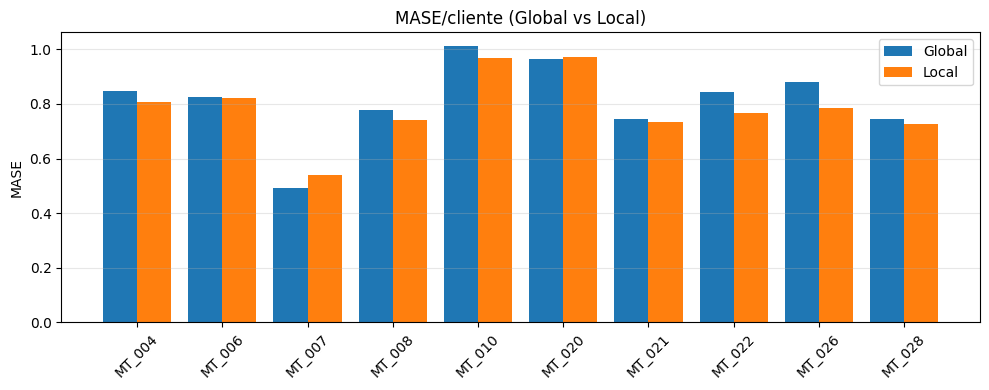

In [22]:
#modelos local vs global
print("Entrenamiento 10 modelos locales")
print("-"*60)

clientes_eval = clientes_sel[:10]
mase_local_por_cliente = {}
mase_global_por_cliente = {}

den_train = (train - train.shift(24)).abs().mean().replace(0, np.nan)

def mase_por_cliente(preds, real, den_train):
    num = (preds - real).abs().mean()
    return (num / den_train).dropna()

mase_global_por_cliente = mase_por_cliente(
    RESULTADOS["DLinear"]["preds"], real_test, den_train
)

for i, cliente in enumerate(clientes_eval):
    print(f"  [{i+1}/10] Cliente {cliente}:")

    train_c = train[[cliente]]
    val_c= val[[cliente]]
    test_c = test[[cliente]]

    mu_c  =train_c.mean()
    std_c = train_c.std().replace(0, 1.0)
    train_cn = (train_c-mu_c)/std_c
    val_cn   = (val_c- mu_c) / std_c

    ds_tr = SeriesOnlyDataset(train_cn, cov_all.loc[train_c.index], L=168, H=24)
    ds_va = SeriesOnlyDataset(val_cn,   cov_all.loc[val_c.index],   L=168, H=24)

    torch.manual_seed(42); np.random.seed(42)
    model = DLinear(L=168, H=24).to(DEVICE)
    model, _ = entrenar_modelo(model, ds_tr, ds_va, epochs=15, lr=1e-3, batch_size=64, device=DEVICE, verbose=False)

    history_seed_c = pd.concat([train_c, val_c])
    pf = make_torch_predict(model, cov_all, 168, 24, mu_c, std_c, DEVICE, series_only=True)
    pr_c, real_c = backtest(pf, test_c, history_seed_c)

    mase_local_por_cliente[cliente] = mase_por_cliente(pr_c, real_c, den_train[[cliente]]).iloc[0]

df_local_global = pd.DataFrame({
    "Cliente": clientes_eval,
    "MASE_global": [mase_global_por_cliente[c] for c in clientes_eval],
    "MASE_local":  [mase_local_por_cliente[c] for c in clientes_eval]
})
df_local_global["Mejora_local_%"] = 100 * (df_local_global["MASE_global"] - df_local_global["MASE_local"]) / df_local_global["MASE_global"]
df_local_global["Ganador"] = df_local_global.apply(lambda r: "Local" if r["MASE_local"] < r["MASE_global"] else "Global", axis=1)

print("\n" + "-"*70)
print(df_local_global.round(4).to_string(index=False))
print("-"*70)
print(f"\nMASE prom. global (10 clientes): {df_local_global['MASE_global'].mean():.4f}")
print(f"MASE prom. local  (10 clientes): {df_local_global['MASE_local'].mean():.4f}")
print(f"Gana local: {(df_local_global['Ganador']=='Local').sum()}/10")
print(f"Gana global: {(df_local_global['Ganador']=='Global').sum()}/10")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(clientes_eval))
ax.bar(x - 0.2, df_local_global["MASE_global"], 0.4, label="Global", color="C0")
ax.bar(x + 0.2, df_local_global["MASE_local"],  0.4, label="Local",  color="C1")
ax.set_xticks(x); ax.set_xticklabels(clientes_eval, rotation=45)
ax.set_ylabel("MASE"); ax.set_title("MASE/cliente (Global vs Local)")
ax.legend(); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

In [ ]:
from neuralforecast import NeuralForecast
from neuralforecast.models import PatchTST
from neuralforecast.losses.pytorch import MAE

# Preparar formato largo (unique_id, ds, y)
df_long = panel_final.stack().reset_index()
df_long.columns = ["ds", "unique_id", "y"]
df_long = df_long.sort_values(["unique_id", "ds"]).reset_index(drop=True)

train_long = df_long[df_long.ds <= "2014-06-30 23:00:00"]
val_long   = df_long[(df_long.ds >= "2014-07-01 00:00:00") &
                     (df_long.ds <= "2014-09-30 23:00:00")]

print(f"Train long: {train_long.shape}  | Val long: {val_long.shape}")

train_val_long = pd.concat([train_long, val_long])

print("Entrenando PatchTST...")
nf = NeuralForecast(
    models=[
        PatchTST(
            h=24,
            input_size=168,
            max_steps=800,
            batch_size=128,
            learning_rate=1e-3,
            valid_loss=MAE(),
            early_stop_patience_steps=50,
            enable_progress_bar=True,
        )
    ],
    freq="h",
)
nf.fit(train_val_long, val_size=2208)


print("\nCross-validation (92 ventanas)")
cv_results = nf.cross_validation(
    df=train_val_long,
    n_windows=92,
    step_size=24,
    refit=False
)

cv_results = cv_results.merge(df_long[["unique_id", "ds", "y"]].rename(columns={"y": "y_real"}), on=["unique_id", "ds"], how="left")

preds_patch = cv_results.pivot_table(index="ds", columns="unique_id", values="PatchTST")
real_patch  = cv_results.pivot_table(index="ds", columns="unique_id", values="y_real")
preds_patch = preds_patch[real_patch.columns]

m_patch = metricas(preds_patch, real_patch)
m_patch["MASE"] = mase(preds_patch, real_patch, train, season=24)

print("\n" + "="*60)
print("PATCHTST")
print("="*60)
print(f"  MAE  = {m_patch['MAE']:.2f} kWh")
print(f"  WAPE = {m_patch['WAPE']*100:.2f}%")
print(f"  MASE = {m_patch['MASE']:.4f}")

RESULTADOS["PatchTST"] = {"preds": preds_patch, "metricas": m_patch}

In [ ]:
#vomparacion final
print("="*80)
print("TABLA COMPARATIVA FINAL - TODOS LOS MODELOS")
print("="*80)
print(f"{'Modelo':<22} {'MAE':>8} {'WAPE':>8} {'MASE':>8} {'MASE_Nav':>10}")
print("-"*80)

for nombre in sorted(RESULTADOS.keys()):
    p = RESULTADOS[nombre]["preds"]
    m = RESULTADOS[nombre]["metricas"]
    mase_g = m.get("MASE", mase(p, real_test, train))
    mase_n = mase_semana(p, real_test, train)
    print(f"{nombre:<22} {m['MAE']:>8.2f} {m['WAPE']*100:>7.2f}% {mase_g:>8.4f} {mase_n:>10.4f}")

tabla_final = pd.DataFrame({
    nombre: {
        "MAE": RESULTADOS[nombre]["metricas"]["MAE"],
        "RMSE": RESULTADOS[nombre]["metricas"].get("RMSE", np.nan),
        "WAPE (%)": RESULTADOS[nombre]["metricas"]["WAPE"] * 100,
        "MASE": RESULTADOS[nombre]["metricas"].get("MASE", mase(RESULTADOS[nombre]["preds"], real_test, train)),
        "MASE_Navidad": mase_semana(RESULTADOS[nombre]["preds"], real_test, train)
    }
    for nombre in RESULTADOS
}).T

print("\n" + tabla_final.round(4).to_string())
tabla_final.to_csv("tabla_resultados_final.csv")
print("\nGuardado")

# Investigacion

- nn.LSTM: Capa con implementación de una red neuronal lstm para procesar datos secuenciales y "recordar" la información a largo plazo. (input_size es la dimension de las caracteristicas de la entrada, hidden_size es el no. de características en el estado oculto h, num_layers no. de capas LSTM que se apilan una sobre otra, batch_first si es True la forma del tensor de entrada es (batch, seq, feature) sino es (seq, batch, feature), dropout aplica capa de dropout)). Su salida es que se manejan dos estados internos. La salida se simplifica y propaga el estado oculto, la salida consiste en salidas de la última capa de la red para todos los pasos de tiempo.

  h_n = estado oculto fina del ultimo paso de tiempo para cada capa
  c_n = estado de celda final del "" ""

- nn.GRU: capa de rnn que se basa en Unidades Recurrentes Cerradas, este procesa secuencias de datos en el tiempo y resuelve el problema del gradiente aunque es un poco mas ligero que LSTM. Sus parametros son practimante iguales a nn.LSTM con la excepcion de que ahora se usan capas GRU. La salida es lo mismo que en nn.LSTM. no tiene 'c_n' pero si h_n y esta es igual que en LSTM.

Las dimensiones de las salidas dependen de batch_first en ambas


- nn.TransformerEncoderLayer: implementa una capa de Transformer (codificador, self-attention + red feedforward). d_model es la dimensión de las características de entrada, nhead es el no. de cabezas de la capa oculta en la red feedforward. batch_first: Si es True, la entrada/salida tiene forma (batch, seq, feature); por defecto es False (seq, batch, feature). d_model es la dimension de caracteristicas de la entrada, nhead el no. de cabezas en el mecanismo de atencion multi cabeza, dim_feedforward es la dimension  de la capa oculta en la red feedforwrd. bath_first, puesto como True hace que la entrada tenga la forma (batch,seq, feature) y por default es False, haciendo que esta sea (seq, batch, feature).

Lo de la codificación posicional consiste en que el mecanismo self attention no varia con la posicion, por esto se teiene que inyectar la informacion en el orden de secuencia.

- NeuralForecast y StatsForecast:Estas librerias toman dataframes como entradas, estos deben ser en formato largo con 3 columnas. unique_id es el id de la serie temporal, ds es el timestamp y y es el valor objetvo a predecir
      
    - cross_validation: hace la validacion de rolling-origin para evlauar si el modelo rinde bien o no. n_windows es el no. de ventanas de validacion, step_size es el no. de pasos de tiempo entre las ventanas y refit ve si se puede reentrenar el modelo en cada ventana dependiendo de si es True o False, se usa para predecir tods las ventanas, en caso sea un entero se entrena cada x ventanas.

- BaseChronosPipeline.predict_quantiles: genera predcciones de series de tiempo (puede ser de 1 o mas) la entrada es el "contexto historico" de la serie (osea el tensor o lista de tensores), prediction_lenght es el no. de pasos que se predericirán. y quintele_levels es de los niveles de cuantiles para los uqe se quiere una predccion.


- modelo local vs global: el local significa que es uno por serie, util para series que son bastante distitnats entre si pero su costo es alto y no saca provecho de patrones compartidos (para esto sería statsforecast). goblal es un solo modelo para todas las seires este si aprovecha los patrones, con una eficienci mayor y manejas las series cortas bastante bien (neuralforecast).

- teacherForcing en modelos autoregresivos y seq2seq: Estrategia de entrenamiento que alimenta al modelo con el valor real del paso anterior, se  hace con todos. Esto hace que el eentrenamiento sea mas rapido y estable pero tambein hace que pueda haber cierto sesgo por que da una discrepacia entre entremaiento e inferencia.

- RevIN: Reversible Instance Normalization, tecnica de normalizacion que en cada ventana resta la media y divide con desviacion estandar y al final hace un inverso para ver bien la escala. Esto ayuda con que aprenda patrones estacionales y se aplica al nivel real de la serie a futuro.
- pinball loss y realcion con cuantiles: Es una funcion de perdida que se usa en la regresion cuantilica, penalizando subestimaciones y sobreestimaciones, haciendo minimizacion. Asi se evita que prediga el valor del cuantil con la distribciuon condicional,

- MASE vs WAPE: Mean Absolute Scaled Error es la normalizacion del MAE del modelo por el de un metodo naive de refernecia, No tiene escala y se puede comparar el rendimiento de las series con diversas unidades. Si el valor de este es menor a 1 entonces el modelo evaluado es mejor que el naive. Weighted Absolute Percent Error es la suma de los errores absolutos dividido con la suma de los valores reales absolutos. la diferencia entre estos es que WAPE no se compara con un benchmark sino que la desviacion relativa y que es sensible a la escala de datos.

#Discusion

- Modelo ganador: NLinear con un MASE de 0.9143 y DLinear con 0.9161, superando al seasonal Naive de 24h y 168h con un MASE del 1.066 y 1.14 respectivamente. Presentando tambien mejoras en sus respecivos MAEs. Estos dos modelos tienen solo 8000 y 4000 parametros y no tardan tanto tiempo en entrenar sin embargo la mejora de MAE en DLinear es bastante baja a pesar de la mejora en MASE no se justifica tanto a diferencia de como sería en un SN24 robusto.
- Replica DLinear: Si se replica pero